# Exercise 15.4 – Von Beobachtungen zu Fehlerregeln

## Ziel und offizielle Anforderungen
Je Fehlertyp eine Python-Regelfunktion aus den Schwellen von 15.2/15.3 erstellen, gegen die Labels mit einer Confusion-Matrix bewerten, einen flachen Entscheidungsbaum trainieren und beide Ansätze hinsichtlich Ergebnis und Erklärbarkeit für Prozessingenieure vergleichen.

Quelle: [offizielles Kursmanuskript, Exercise 15.4](https://noxthot.github.io/ws26_industrial_datascience_manuscript/2_act2/2_self_study_session2.html), abgerufen am 21.11.2026. Abnahme: vier Regelfunktionen, vier flache Bäume, acht Confusion-Matrizen und begründeter Vergleich. Notebook und HTML bilden die Lösung; CSVs und Baumtexte machen sie nachprüfbar. Keine weitere Aufgabe bearbeitet.

## Daten und Methode
Unveränderte 20.000 XAI-Drilling-Beobachtungen (Kaggle-Version 1, CC BY-NC-SA 4.0; Herkunft und SHA256 siehe `data/raw/XAI_DRILLING_SOURCE.md`). Die vier Labels werden getrennt binär bewertet; Mehrfachfehler bleiben erhalten. ID und alle Fehlerflags sind keine Eingangsmerkmale. Kaggle-Registrierung weiterhin offen.

Eine Regel verknüpft Bedingungen mit UND/ODER. Ein Entscheidungsbaum lernt schrittweise Trennungen nach Merkmalen; seine Blätter liefern die vorhergesagte Klasse. Maximale Tiefe 3 begrenzt die Komplexität, Seed 42 sichert Wiederholbarkeit. Keine Optimierung oder Gewichtung. Numerische Merkmale bleiben in Originaleinheiten, Kategorien werden ohne künstliche Rangfolge auf TRAIN mit One-Hot kodiert. Skalierung ist für diese Bäume nicht erforderlich.

Ein gemeinsamer ungefährer 80/20-Gruppensplit hält identische Eingangsmerkmale zusammen. Es wird nicht nach Labels geschichtet; Häufigkeiten werden ausgewiesen. Nur TRAIN wird zum Fitten der Bäume benutzt.

**Grenze der Bewertung:** Die Regeln und die Wahl der Eingangsmerkmale beruhen bereits auf der Exploration des gesamten Bestands. TEST ist daher für die Regeln kein unabhängiger Prüfbestand; auch der Vergleich ist eine rückblickende Demonstration. Keine Aussage über neue reale Daten oder unverzerrte Generalisierung.

## Festgelegte Regeln vor dem Vergleich
- BEF: vc ≤ 22 m/min UND Kühlung ≤ 25 %, aus 15.2/15.3.
- CCF: gemeinsamer Bereich aller sieben numerischen Merkmale der CCF-positiven Zeilen aus 15.2. Das ist bewusst eine einfache Bereichsregel; einzelne Minima/Maxima identifizieren CCF nicht eindeutig.
- FWF: je Material vc höchstens 16,67 (K), 29,70 (N), 21,99 (P) m/min UND vf mindestens 149 (K), 206 (N), 127 (P) mm/min. Aus den materialbezogenen Bereichen in 15.2, keine nachträgliche TEST-Anpassung.
- WDF: Bohrertyp passt nicht zu den beobachteten Paaren P/N, K/H, N/W. Aus der Kategorienauswertung in 15.2.

Alle Grenzen einschließlich Endpunkte; keine geschätzten Ausfallwahrscheinlichkeiten. Kleine K/P-FWF-Gruppen begrenzen besonders diese Regel.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sessions.ch15.drilling_data import load_data, verify_file, SUBGROUPS
from sessions.ch15.rule_models import evaluate, SEED
output = Path("outputs/ch15/exercise_15_4")
output.mkdir(parents=True, exist_ok=True)
data = load_data()
metrics, predictions, split, counts, models, tree_texts = evaluate(data)
for name,table in {"metrics":metrics,"predictions":predictions,"split":split,"class_counts":counts}.items():
    table.to_csv(output / f"{name}.csv",index=False)
for flag,text in tree_texts.items():
    (output / f"tree_{flag.lower()}.txt").write_text(text,encoding="utf-8")
summary = {"rows":len(data),"train":int(split.Split.eq("TRAIN").sum()),"test":int(split.Split.eq("TEST").sum()),"seed":SEED,"max_depth":3,"raw_sha256":verify_file(),"evaluation":"retrospective; rules informed by entire dataset"}
(output / "summary.json").write_text(json.dumps(summary,indent=2),encoding="utf-8")
display(pd.DataFrame([summary]).drop(columns=["raw_sha256","evaluation"]),counts)


,rows,train,test,seed,max_depth
0,20000,15998,4002,42,3


,Fehlertyp,TRAIN,TEST
0,BEF,157,58
1,CCF,280,64
2,FWF,222,56
3,WDF,242,58


## Ergebnisse
Die Confusion-Matrix zählt korrekte negative (TN), falsch positive (FP), übersehene positive (FN) und korrekt erkannte positive Fälle (TP). Zeilen: tatsächlich, Spalten: vorhergesagt. Recall = TP/(TP+FN), Precision = TP/(TP+FP), F1 ist ihr harmonisches Mittel. Bei leerem Nenner wird hier 0 ausgegeben. Wegen seltener Fehler ist Accuracy allein ungeeignet. Alle Vergleiche verwenden dieselben TEST-Zeilen.

,Fehlertyp,Methode,TN,FP,FN,TP,Precision,Recall,F1
0,BEF,Regel,3625,319,0,58,0.1538,1.0000,0.2667
1,BEF,Baum,3944,0,29,29,1.0000,0.5000,0.6667
2,CCF,Regel,126,3812,0,64,0.0165,1.0000,0.0325
3,CCF,Baum,3935,3,12,52,0.9455,0.8125,0.8739
4,FWF,Regel,3944,2,0,56,0.9655,1.0000,0.9825
5,FWF,Baum,3946,0,5,51,1.0000,0.9107,0.9533
6,WDF,Regel,3944,0,0,58,1.0000,1.0000,1.0000
7,WDF,Baum,3944,0,58,0,0.0000,0.0000,0.0000


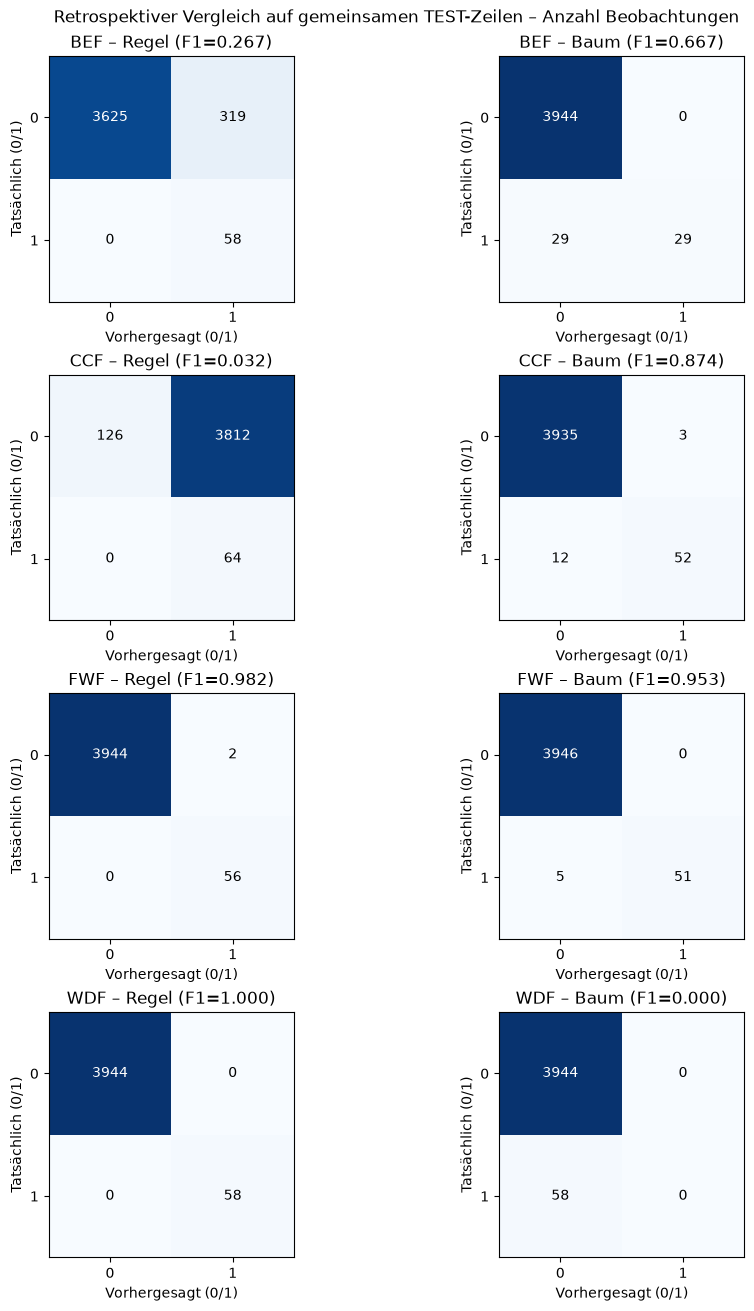

In [2]:
display(metrics.round(4))
fig, axes = plt.subplots(4,2,figsize=(9,13),layout="constrained")
for ax,row in zip(axes.flat,metrics.to_dict("records")):
    matrix = [[row["TN"],row["FP"]],[row["FN"],row["TP"]]]
    ax.imshow(matrix,cmap="Blues",vmin=0,vmax=summary["test"])
    for i in range(2):
        for j in range(2):
            ax.text(j,i,str(matrix[i][j]),ha="center",va="center",color="white" if matrix[i][j]>summary["test"]/2 else "black")
    ax.set(xticks=[0,1],yticks=[0,1],xlabel="Vorhergesagt (0/1)",ylabel="Tatsächlich (0/1)",title=f"{row['Fehlertyp']} – {row['Methode']} (F1={row['F1']:.3f})")
fig.suptitle("Retrospektiver Vergleich auf gemeinsamen TEST-Zeilen – Anzahl Beobachtungen")
fig.savefig(output / "01_confusion_matrices.png",dpi=150,bbox_inches="tight")
plt.show()


## Die gelernten Entscheidungen lesen
Die Baumtexte nennen Merkmal, Grenze und Klasse. One-Hot-Werte ≤ 0,5 bedeuten, dass die Kategorie nicht vorliegt. Die Tiefe ist auf drei begrenzt. Blattklassen sind Mehrheitsentscheidungen, keine physikalischen Gesetze. Die vollständigen Texte werden zusätzlich gespeichert.

In [3]:
for flag,text in tree_texts.items():
    print(f"\n{flag} – Baum, maximale Tiefe 3\n{text}")



BEF – Baum, maximale Tiefe 3
|--- numeric__Cutting speed vc [m/min] <= 16.695
|   |--- class: 1
|--- numeric__Cutting speed vc [m/min] >  16.695
|   |--- numeric__Feed f [mm/rev] <= 0.138
|   |   |--- numeric__Cutting speed vc [m/min] <= 22.000
|   |   |   |--- class: 1
|   |   |--- numeric__Cutting speed vc [m/min] >  22.000
|   |   |   |--- class: 0
|   |--- numeric__Feed f [mm/rev] >  0.138
|   |   |--- numeric__Feed f [mm/rev] <= 0.148
|   |   |   |--- class: 0
|   |   |--- numeric__Feed f [mm/rev] >  0.148
|   |   |   |--- class: 0


CCF – Baum, maximale Tiefe 3
|--- numeric__Cooling [%] <= 37.500
|   |--- numeric__Feed rate vf [mm/min] <= 124.500
|   |   |--- category__Drill Bit Type_W <= 0.500
|   |   |   |--- class: 0
|   |   |--- category__Drill Bit Type_W >  0.500
|   |   |   |--- class: 1
|   |--- numeric__Feed rate vf [mm/min] >  124.500
|   |   |--- numeric__Power Pc [kW] <= 63.905
|   |   |   |--- class: 0
|   |   |--- numeric__Power Pc [kW] >  63.905
|   |   |   |--- cl

## Interpretation und Grenzen
Der Gruppensplit ergibt 15.998 TRAIN- und 4.002 TEST-Zeilen. BEF: Die Regel erkennt alle 58 markierten TEST-Fälle, erzeugt aber 319 Fehlalarme (F1 0,267). Der Baum erkennt 29/58 ohne Fehlalarm (F1 0,667). CCF: Die Bereichsregel erzeugt 3.812 Fehlalarme (F1 0,032); die Merkmalsbox reicht nicht zur Identifikation. Der Baum erreicht F1 0,874 mit 3 FP und 12 FN.

FWF: Regel F1 0,982 (2 FP, 0 FN), Baum F1 0,953 (0 FP, 5 FN). WDF: Die Kategorienregel trifft hier alle 58 markierten Fälle ohne Fehlalarm (F1 1,0). Der ungewichtete flache Baum sagt für alle TEST-Zeilen 0 voraus (58 FN, F1 0). Die Beschränkung auf Tiefe 3 garantiert keine brauchbare Erkennung seltener Kategorienkombinationen. Das Ergebnis wird nicht durch nachträgliche Optimierung verbessert. F1 1,0 bedeutet nur vollständige Übereinstimmung dieser Regel mit den ausgewerteten Labels, keine allgemeine Fehlerfreiheit.

Einem Prozessingenieur würde ich zunächst die kurzen BEF- und WDF-Regeln erklären: Einheiten und Bedingungen sind direkt sichtbar. Die CCF-Box mit 14 Grenzen ist weniger anschaulich; dort ist ein kurzer Baumtext meist leichter zu diskutieren. Für FWF müssen Materialunterschiede erklärt werden. Keine Methode ist dadurch fachlich oder allgemein überlegen. Vor betrieblichem Einsatz wären unabhängige Daten und eine fachliche Prüfung der Bedingungen erforderlich.

Synthetische Daten, überlappende Labels und seltene Fehler begrenzen Aussagen. Der gemeinsame Gruppensplit verhindert identische Merkmalszeilen auf beiden Seiten, beseitigt aber nicht die bereits erfolgte Gesamtdatenexploration. Keine Schwellen nach TEST-Ergebnissen angepasst, keine externe Validierung oder Kausalität nachgewiesen. Originaldaten unverändert. Kaggle-Registrierung weiterhin offen.

KI-Unterstützung: Codex hat Anforderungen, Code, Ausführung und technische Prüfung unterstützt. Wissenschaftlicher Human Review für 15.4 steht aus. **AWAITING HUMAN REVIEW.**